In [ ]:
Got it — let’s slow this down and make the chain rule steps explicit so you see why we compute \(\frac{\partial L}{\partial y}\) as well as \(f'(z)\).

---

### 1. Setup
For a single neuron:

\[
z = w \cdot x + b, \quad y = f(z), \quad L = \text{loss}(y)
\]

- \(z\): linear combination of inputs  
- \(y\): activation output  
- \(L\): loss function

---

### 2. Goal in Backpropagation
We want gradients like:

\[
\frac{\partial L}{\partial w}, \quad \frac{\partial L}{\partial b}
\]

so we can update weights.

---

### 3. Chain Rule Expansion
Take \(\frac{\partial L}{\partial w}\):

\[
\frac{\partial L}{\partial w} = \frac{\partial L}{\partial y} \cdot \frac{\partial y}{\partial z} \cdot \frac{\partial z}{\partial w}
\]

- \(\frac{\partial L}{\partial y}\): how the loss changes with respect to the neuron’s output  
- \(\frac{\partial y}{\partial z} = f'(z)\): derivative of activation  
- \(\frac{\partial z}{\partial w} = x\): input value

So:

\[
\frac{\partial L}{\partial w} = \underbrace{\frac{\partial L}{\partial y}}_{\text{loss sensitivity}} \cdot \underbrace{f'(z)}_{\text{activation slope}} \cdot \underbrace{x}_{\text{input}}
\]

---

### 4. Why \(\frac{\partial L}{\partial y}\) is Needed
- You already understood \(f'(z)\): it tells us how sensitive the neuron’s output is to changes in \(z\).  
- But the network doesn’t care about \(y\) in isolation — it cares about how the **loss** changes.  
- That’s why we need \(\frac{\partial L}{\partial y}\): it connects the neuron’s output back to the loss function.  

Without \(\frac{\partial L}{\partial y}\), you’d only know the slope of the activation, not whether increasing \(y\) makes the loss bigger or smaller.

---

### 5. Numeric Mini-Demo
Suppose:
- \(f(z) = \text{sigmoid}(z)\)  
- Loss: \(L = \frac{1}{2}(y - t)^2\) with target \(t\)

Then:

\[
\frac{\partial L}{\partial y} = (y - t)
\]

\[
\frac{\partial y}{\partial z} = f'(z) = y(1-y)
\]

So:

\[
\frac{\partial L}{\partial w} = (y - t) \cdot y(1-y) \cdot x
\]

👉 Notice how both pieces matter:  
- \((y - t)\) tells you if the neuron overshot or undershot the target.  
- \(y(1-y)\) tells you how responsive the activation is at that point.  
- Together they scale the gradient update.

---

### 🎯 Takeaway
We compute \(\frac{\partial L}{\partial y}\) because the chain rule requires it: the gradient must flow from the **loss** back through the activation. \(f'(z)\) alone isn’t enough — it only gives local slope, not the loss sensitivity.

---

Would you like me to show this with a **Python snippet** that prints out each term (\(\frac{\partial L}{\partial y}\), \(f'(z)\), and the final gradient) for a toy neuron? That way you can see the numbers side

In [ ]:
import numpy as np

# ----- Setup -----
# Input, weight, bias, target
x = 0.5
w = 0.8
b = 0.2
t = 1.0   # target output

# ----- Forward pass -----
z = w * x + b
y = 1 / (1 + np.exp(-z))   # sigmoid activation
L = 0.5 * (y - t)**2       # mean squared error loss

# ----- Backpropagation terms -----
# dL/dy : sensitivity of loss wrt output
dL_dy = (y - t)

# dy/dz : derivative of activation
dy_dz = y * (1 - y)

# dz/dw : derivative of linear part wrt weight
dz_dw = x

# ----- Final gradient -----
dL_dw = dL_dy * dy_dz * dz_dw

# ----- Print results -----
print(f"z = {z:.4f}")
print(f"y (sigmoid output) = {y:.4f}")
print(f"Loss L = {L:.4f}")
print(f"dL/dy = {dL_dy:.4f}")
print(f"dy/dz = {dy_dz:.4f}")
print(f"dz/dw = {dz_dw:.4f}")
print(f"dL/dw (final gradient) = {dL_dw:.4f}")

In [ ]:
What you’ll see when you run it
- dL/dy → tells you if the neuron overshot or undershot the target.
- dy/dz → slope of the activation at that point.
- dz/dw → input scaling.
- dL/dw → the actual gradient used to update the weight.
This way you can numerically trace how backpropagation combines the loss sensitivity and activation slope.
👉 Do you want me to also show the same code with ReLU activation side‑by‑side, so you can compare how gradients behave differently?


                           How RELU helps in finding the gradient

In [ ]:
import numpy as np

# ----- Setup -----
x = 0.5
w = 0.8
b = 0.2
t = 1.0   # target output

# ----- Sigmoid activation -----
z_sig = w * x + b
y_sig = 1 / (1 + np.exp(-z_sig))
L_sig = 0.5 * (y_sig - t)**2

dL_dy_sig = (y_sig - t)
dy_dz_sig = y_sig * (1 - y_sig)
dz_dw = x
dL_dw_sig = dL_dy_sig * dy_dz_sig * dz_dw

# ----- ReLU activation -----
z_relu = w * x + b
y_relu = np.maximum(0, z_relu)
L_relu = 0.5 * (y_relu - t)**2

dL_dy_relu = (y_relu - t)
dy_dz_relu = 1.0 if z_relu > 0 else 0.0
dL_dw_relu = dL_dy_relu * dy_dz_relu * dz_dw

# ----- Print results -----
print("=== Sigmoid ===")
print(f"z = {z_sig:.4f}, y = {y_sig:.4f}, Loss = {L_sig:.4f}")
print(f"dL/dy = {dL_dy_sig:.4f}, dy/dz = {dy_dz_sig:.4f}, dz/dw = {dz_dw:.4f}")
print(f"dL/dw (gradient) = {dL_dw_sig:.4f}")

print("\n=== ReLU ===")
print(f"z = {z_relu:.4f}, y = {y_relu:.4f}, Loss = {L_relu:.4f}")
print(f"dL/dy = {dL_dy_relu:.4f}, dy/dz = {dy_dz_relu:.4f}, dz/dw = {dz_dw:.4f}")
print(f"dL/dw (gradient) = {dL_dw_relu:.4f}")

In [ ]:
What you’ll observe
- Sigmoid:
- Gradient includes the term y(1-y), which can shrink toward 0 when y is near 0 or 1 → vanishing gradient problem.
- ReLU:
- Gradient is either 1 (if z>0) or 0 (if z\leq 0).
- Keeps gradients flowing for positive inputs, but can “die” for negative inputs (gradient = 0).

👉 This side‑by‑side run will give you numeric proof of why ReLU often trains faster than sigmoid: gradients don’t vanish as easily.
Would you like me to extend this demo to plot gradient curves for sigmoid vs ReLU across a range of inputs, so you can visually see why one vanishes and the other doesn’t


                               Gradient without activation function

In [ ]:
Gradient without activation function
Here’s a copy‑paste Python snippet showing backpropagation when there’s no activation: the neuron output is purely linear, y=z=w\cdot x+b. Mean squared 
error loss is used.
import numpy as np

# ----- Setup -----
x = 0.5
w = 0.8
b = 0.2
t = 1.0  # target output

# ----- Forward pass -----
z = w * x + b   # linear output
y = z           # no activation function
L = 0.5 * (y - t)**2  # mean squared error loss

# ----- Backpropagation terms -----
dL_dy = (y - t)    # loss sensitivity to output
dy_dz = 1.0        # since y = z, derivative is 1
dz_dw = x          # derivative of z w.r.t. w

# ----- Final gradient -----
dL_dw = dL_dy * dy_dz * dz_dw

# ----- Print results -----
print(f"z = {z:.4f}")
print(f"y = {y:.4f}")
print(f"Loss L = {L:.4f}")
print(f"dL/dy = {dL_dy:.4f}")
print(f"dy/dz = {dy_dz:.4f}")
print(f"dz/dw = {dz_dw:.4f}")
print(f"dL/dw (final gradient) = {dL_dw:.4f}")



What this shows
- No activation slope: Because y=z, the derivative dy/dz=1. The activation contributes no scaling to the gradient.
- Gradient composition: The chain rule still applies:
\frac{\partial L}{\partial w}=\frac{\partial L}{\partial y}\cdot \frac{\partial y}{\partial z}\cdot \frac{\partial z}{\partial w}=(y-t)\cdot 1\cdot x.
- Learning implication: A deep network without activations is just a single linear transformation; backprop works, but the model can only learn linear
mappings, limiting expressivity.


In [ ]:
Exactly, Rama — you’ve spotted the key geometric difference 👌.

---

### 🔹 Without activation
- The neuron is just:  
  \[
  y = w \cdot x + b
  \]
- That’s a straight line when you plot **output vs input**.  
- Stack multiple such layers → still collapses to one big linear transformation. The whole network can only learn linear mappings.

---

### 🔹 With activation
- Now the neuron is:  
  \[
  y = f(w \cdot x + b)
  \]
- Because \(f\) is nonlinear (sigmoid, tanh, ReLU, etc.), the plot of **output vs input** bends into a curve.  
- Example:  
  - **Sigmoid**: S‑shaped curve, squashes values between 0 and 1.  
  - **Tanh**: Similar but squashes between −1 and 1.  
  - **ReLU**: Piecewise linear — flat at 0 for negatives, slope 1 for positives.  

---

### 🔍 Why this matters
- **Linear line only** → network can’t capture complex patterns (e.g., XOR problem).  
- **Curved/nonlinear output** → network can approximate nonlinear functions, which is why deep nets are powerful universal approximators.  

---

### ⚙️ Quick Python demo (copy‑paste ready)
This shows the difference in plots:

```python

👉 Run this and you’ll see:
- Straight line for the linear case.  
- Curved S‑shape for sigmoid.  
- Piecewise line for ReLU.  

---

Would you like me to extend this demo to **tanh and leaky ReLU** as well, so you have a recruiter‑ready comparison of the most common activations side by side?


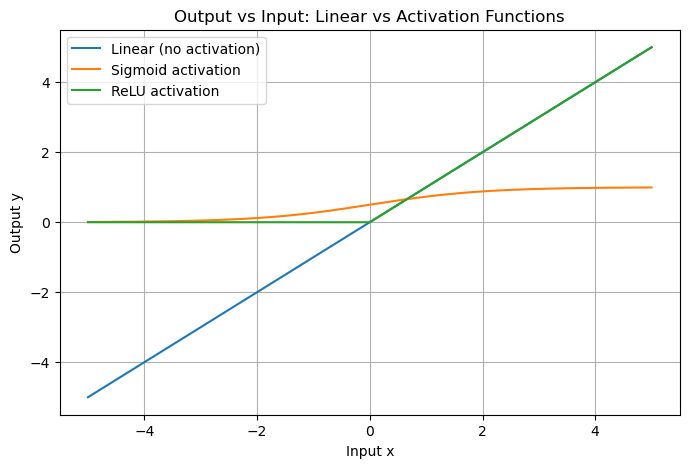

In [6]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 200)
w, b = 1.0, 0.0

# Without activation
y_linear = w * x + b

# With sigmoid activation
y_sigmoid = 1 / (1 + np.exp(-(w * x + b)))

# With ReLU activation
y_relu = np.maximum(0, w * x + b)

plt.figure(figsize=(8,5))
plt.plot(x, y_linear, label="Linear (no activation)")
plt.plot(x, y_sigmoid, label="Sigmoid activation")
plt.plot(x, y_relu, label="ReLU activation")
plt.legend()
plt.title("Output vs Input: Linear vs Activation Functions")
plt.xlabel("Input x")
plt.ylabel("Output y")
plt.grid(True)
plt.show()

